# Bloque 2 · Calidad de datos, análisis exploratorio e ingeniería de características

**Unidad didáctica:** Diseño de Soluciones de Inteligencia Artificial (CERTUS)

Caso de trabajo: **una tienda online quiere saber qué clientes dejarán de comprar** (variable objetivo `se_fue`). Es el mismo caso del bloque 1.

En este cuaderno harás, paso a paso, lo que pide la **Evidencia 2**:

| Parte del informe AA2 | Sección del cuaderno |
|---|---|
| Descripción de librerías | 1 |
| Diccionario de datos | 3 |
| Calidad de datos (limpieza y transformación) | 4 |
| Análisis univariado | 5 |
| Análisis bivariado | 6 |
| Hipótesis sobre la data | 7 |
| Ingeniería de características | 8 |
| Reporte y reproducibilidad | 9 |

**Importante:** los datos son **simulados** para practicar. Tienen errores a propósito (nulos, duplicados, textos mal escritos, valores atípicos), como los datos reales. Con los datos de su proyecto harán el mismo proceso.

## 0. Preparación

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.decomposition import PCA
from sklearn.feature_selection import mutual_info_classif

pd.set_option("display.max_columns", 30)
print("Listo")

Listo


## 1. Python para la IA: las 3 librerías del bloque

| Librería | Para qué sirve | Funciones que usaremos |
|---|---|---|
| **pandas** | Leer, limpiar y transformar tablas (DataFrames) | `read_csv`, `head`, `info`, `describe`, `isnull`, `fillna`, `drop_duplicates`, `groupby`, `cut` |
| **matplotlib** | Hacer gráficos | `hist`, `bar`, `boxplot`, `scatter`, `imshow` |
| **scikit-learn** | Preprocesar datos y crear modelos | `MinMaxScaler`, `StandardScaler`, `PCA`, `mutual_info_classif` |

Un **DataFrame** es una tabla: cada **fila** es un caso (un cliente) y cada **columna** es una variable.

In [2]:
# Mini ejemplo de pandas
mini = pd.DataFrame({"cliente": ["Ana", "Luis", "Rosa"], "edad": [25, 41, 33], "compras": [3, 8, 5]})
print(mini)
print("\nPromedio de compras:", mini["compras"].mean())
print("\nClientes con más de 4 compras:")
print(mini[mini["compras"] > 4])

  cliente  edad  compras
0     Ana    25        3
1    Luis    41        8
2    Rosa    33        5

Promedio de compras: 5.333333333333333

Clientes con más de 4 compras:
  cliente  edad  compras
1    Luis    41        8
2    Rosa    33        5


## 2. Cargar los datos

Con datos reales se usa `pd.read_csv("archivo.csv")` o `pd.read_excel("archivo.xlsx")`. Aquí los **generamos** con una semilla fija (`42`), así todos obtienen exactamente la misma tabla.

**Ejecuta esta celda sin modificarla.**

In [3]:
rng = np.random.default_rng(42)
n = 1000
distritos = ["Lima", "Surco", "Miraflores", "San Juan de Lurigancho", "Comas", "Los Olivos"]
edad = np.clip(rng.normal(36, 11, n), 18, 75).round()
distrito = rng.choice(distritos, n, p=[.22, .18, .12, .2, .14, .14])
canal = rng.choice(["App", "Web", "Tienda"], n, p=[.45, .35, .2])
compras_6m = rng.poisson(6, n)
monto_total = (compras_6m * rng.gamma(9, 9, n)).round(2)
dias_ultima_compra = np.clip(rng.exponential(40, n), 0, 365).round()
reclamos = rng.poisson(0.6, n)
usa_cupon = rng.choice(["Sí", "No"], n, p=[.4, .6])
fecha_registro = pd.to_datetime("2022-01-01") + pd.to_timedelta(rng.integers(0, 1400, n), unit="D")

# Variable objetivo: depende de recencia, reclamos, compras y cupón (el canal NO influye)
z = -1.6 + 0.035 * dias_ultima_compra + 0.7 * reclamos - 0.15 * compras_6m - 0.8 * (usa_cupon == "Sí")
se_fue = (rng.random(n) < 1 / (1 + np.exp(-z))).astype(int)

clientes = pd.DataFrame({
    "id_cliente": [f"C{i:04d}" for i in range(1, n + 1)],
    "edad": edad, "distrito": distrito, "canal": canal,
    "compras_6m": compras_6m, "monto_total": monto_total,
    "dias_ultima_compra": dias_ultima_compra, "reclamos": reclamos,
    "usa_cupon": usa_cupon, "fecha_registro": fecha_registro.strftime("%Y-%m-%d"),
    "se_fue": se_fue,
})

# Problemas de calidad introducidos a propósito (como en datos reales)
idx = rng.choice(n, 50, replace=False); clientes.loc[idx, "edad"] = np.nan
idx = rng.choice(n, 30, replace=False); clientes.loc[idx, "monto_total"] = np.nan
idx = rng.choice(n, 60, replace=False)
clientes.loc[idx, "distrito"] = clientes.loc[idx, "distrito"].str.upper()
idx = rng.choice(n, 40, replace=False)
clientes.loc[idx, "distrito"] = clientes.loc[idx, "distrito"].str.lower() + " "
idx = rng.choice(n, 6, replace=False); clientes.loc[idx, "monto_total"] = clientes.loc[idx, "monto_total"] * 12
clientes = pd.concat([clientes, clientes.sample(15, random_state=1)], ignore_index=True)

print("Filas y columnas:", clientes.shape)
clientes.head()

Filas y columnas: (1015, 11)


,id_cliente,edad,distrito,canal,compras_6m,monto_total,dias_ultima_compra,reclamos,usa_cupon,fecha_registro,se_fue
0,C0001,39.0,San Juan de Lurigancho,Web,2,315.41,22.0,0,No,2022-12-27,1
1,C0002,25.0,Surco,Tienda,11,883.61,4.0,2,No,2025-01-03,0
2,C0003,44.0,Miraflores,App,7,553.75,11.0,0,No,2023-03-31,0
3,C0004,NaN,Miraflores,Web,6,268.90,34.0,0,No,2024-04-26,0
4,C0005,18.0,Lima,Web,5,327.99,155.0,1,Sí,2024-02-18,1


### Primer vistazo: tipos de datos y valores faltantes

In [4]:
clientes.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1015 entries, 0 to 1014
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id_cliente          1015 non-null   object 
 1   edad                964 non-null    float64
 2   distrito            1015 non-null   object 
 3   canal               1015 non-null   object 
 4   compras_6m          1015 non-null   int64  
 5   monto_total         985 non-null    float64
 6   dias_ultima_compra  1015 non-null   float64
 7   reclamos            1015 non-null   int64  
 8   usa_cupon           1015 non-null   object 
 9   fecha_registro      1015 non-null   object 
 10  se_fue              1015 non-null   int64  
dtypes: float64(3), int64(3), object(5)
memory usage: 87.4+ KB


In [5]:
clientes.describe().round(1)

,edad,compras_6m,monto_total,dias_ultima_compra,reclamos,se_fue
count,964.0,1015.0,985.0,1015.0,1015.0,1015.0
mean,35.8,5.9,514.7,41.2,0.6,0.3
std,10.4,2.5,734.2,41.0,0.8,0.5
min,18.0,0.0,0.0,0.0,0.0,0.0
25%,28.0,4.0,286.9,11.5,0.0,0.0
50%,36.0,6.0,428.3,29.0,0.0,0.0
75%,42.0,7.0,598.6,58.0,1.0,1.0
max,71.0,18.0,18844.8,287.0,5.0,1.0


## 3. Diccionario de datos

Es la **ficha de cada variable**: qué significa, de qué tipo es, qué valores puede tomar y si tiene faltantes. Es lo primero del informe y lo que más se evalúa en el criterio *Descripción de variables*.

**Tipos de variables:**

```text
Numérica continua     puede tener decimales             monto_total, edad
Numérica discreta     cuenta cosas (enteros)            compras_6m, reclamos
Categórica nominal    categorías sin orden              distrito, canal
Categórica ordinal    categorías con orden              tramo de edad (joven < adulto < mayor)
Binaria               solo dos valores                  usa_cupon, se_fue
Fecha                 un momento en el tiempo           fecha_registro
Identificador         solo distingue filas, NO predice  id_cliente
```

La parte automática (tipo, nulos, rango) la calcula Python. La **descripción** la escribe el equipo.

In [6]:
descripciones = {
    "id_cliente": "Código único del cliente",
    "edad": "Edad del cliente en años",
    "distrito": "Distrito de residencia",
    "canal": "Canal de compra más usado",
    "compras_6m": "Número de compras en los últimos 6 meses",
    "monto_total": "Monto gastado en los últimos 6 meses (S/)",
    "dias_ultima_compra": "Días desde la última compra (recencia)",
    "reclamos": "Número de reclamos registrados",
    "usa_cupon": "Si usó algún cupón de descuento",
    "fecha_registro": "Fecha en que se registró en la tienda",
    "se_fue": "TARGET: 1 si dejó de comprar, 0 si sigue",
}
tipos = {
    "id_cliente": "Identificador", "edad": "Numérica continua", "distrito": "Categórica nominal",
    "canal": "Categórica nominal", "compras_6m": "Numérica discreta", "monto_total": "Numérica continua",
    "dias_ultima_compra": "Numérica discreta", "reclamos": "Numérica discreta", "usa_cupon": "Binaria",
    "fecha_registro": "Fecha", "se_fue": "Binaria (target)",
}

filas = []
for col in clientes.columns:
    serie = clientes[col]
    if pd.api.types.is_numeric_dtype(serie):
        rango = f"{serie.min():g} a {serie.max():g}"
    else:
        valores = serie.dropna().unique()
        rango = f"{len(valores)} valores distintos" if len(valores) > 6 else ", ".join(map(str, valores))
    filas.append({
        "variable": col,
        "descripción": descripciones[col],
        "tipo": tipos[col],
        "rango o valores": rango,
        "% nulos": round(serie.isnull().mean() * 100, 1),
    })

diccionario = pd.DataFrame(filas)
diccionario

,variable,descripción,tipo,rango o valores,% nulos
0,id_cliente,Código único del cliente,Identificador,1000 valores distintos,0.0
1,edad,Edad del cliente en años,Numérica continua,18 a 71,5.0
2,distrito,Distrito de residencia,Categórica nominal,18 valores distintos,0.0
3,canal,Canal de compra más usado,Categórica nominal,"Web, Tienda, App",0.0
4,compras_6m,Número de compras en los últimos 6 meses,Numérica discreta,0 a 18,0.0
5,monto_total,Monto gastado en los últimos 6 meses (S/),Numérica continua,0 a 18844.8,3.0
6,dias_ultima_compra,Días desde la última compra (recencia),Numérica discreta,0 a 287,0.0
7,reclamos,Número de reclamos registrados,Numérica discreta,0 a 5,0.0
8,usa_cupon,Si usó algún cupón de descuento,Binaria,"No, Sí",0.0
9,fecha_registro,Fecha en que se registró en la tienda,Fecha,721 valores distintos,0.0


**Observa:** el diccionario ya revela problemas. `edad` y `monto_total` tienen nulos, y `distrito` tiene más valores distintos de los que debería (6 distritos). Eso se corrige en la sección 4.

## 4. Calidad de datos: limpieza y transformación

Revisamos 5 problemas típicos, en este orden:

```text
1. Duplicados          filas repetidas
2. Inconsistencias     el mismo valor escrito de varias formas
3. Nulos               valores faltantes
4. Valores atípicos    valores muy lejanos al resto
5. Tipos de dato       fechas guardadas como texto, etc.
```

### 4.1 Duplicados

In [7]:
print("Filas duplicadas:", clientes.duplicated().sum())
datos = clientes.drop_duplicates().copy()
print("Filas después de eliminarlos:", len(datos))

Filas duplicadas: 15
Filas después de eliminarlos: 1000


### 4.2 Inconsistencias en texto

In [8]:
print("ANTES:")
print(datos["distrito"].value_counts())

datos["distrito"] = datos["distrito"].str.strip().str.title()   # quita espacios y pone Mayúscula Inicial
datos["distrito"] = datos["distrito"].replace({"San Juan De Lurigancho": "San Juan de Lurigancho"})

print("\nDESPUÉS:")
print(datos["distrito"].value_counts())

ANTES:
distrito
Lima                       193
San Juan de Lurigancho     161
Surco                      153
Los Olivos                 138
Comas                      129
Miraflores                 127
LIMA                        19
lima                        12
SAN JUAN DE LURIGANCHO      11
COMAS                       11
SURCO                        9
surco                        8
comas                        8
LOS OLIVOS                   7
san juan de lurigancho       6
miraflores                   4
los olivos                   2
MIRAFLORES                   2
Name: count, dtype: int64

DESPUÉS:
distrito
Lima                      224
San Juan de Lurigancho    178
Surco                     170
Comas                     148
Los Olivos                147
Miraflores                133
Name: count, dtype: int64


### 4.3 Valores nulos

```text
¿Qué hacer con los nulos?
   Pocos nulos (< 5 %) y numérica     → rellenar con la MEDIANA (no la afectan los atípicos)
   Pocos nulos y categórica           → rellenar con la MODA (el valor más frecuente)
   Muchos nulos (> 40 %)              → evaluar eliminar la columna
   El nulo significa algo             → crear una categoría "Sin dato" o una columna 0/1
```

% de nulos por columna:
edad           5.0
monto_total    3.0
dtype: float64


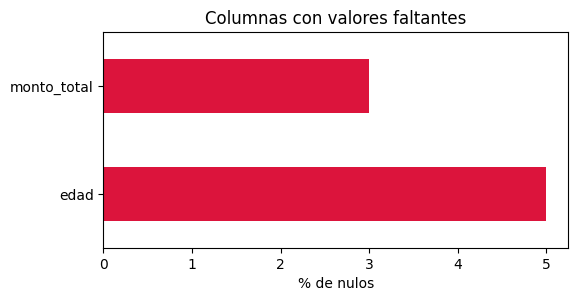

In [9]:
nulos = datos.isnull().mean() * 100
print("% de nulos por columna:")
print(nulos[nulos > 0].round(1))

plt.figure(figsize=(6, 2.8))
nulos[nulos > 0].plot(kind="barh", color="crimson")
plt.xlabel("% de nulos"); plt.title("Columnas con valores faltantes"); plt.show()

In [10]:
mediana_edad = datos["edad"].median()
mediana_monto = datos["monto_total"].median()
datos["edad"] = datos["edad"].fillna(mediana_edad)
datos["monto_total"] = datos["monto_total"].fillna(mediana_monto)

print("Mediana usada para edad:", mediana_edad, "| para monto:", mediana_monto)
print("Nulos restantes:", datos.isnull().sum().sum())

Mediana usada para edad: 36.0 | para monto: 428.03
Nulos restantes: 0


### 4.4 Valores atípicos (outliers) con la regla del IQR

```text
Q1 = percentil 25        Q3 = percentil 75        IQR = Q3 − Q1
Límite superior = Q3 + 1.5 · IQR
Límite inferior = Q1 − 1.5 · IQR
Un valor fuera de esos límites es "atípico".
```

**Atípico no siempre es error.** Un cliente que gasta mucho puede ser real. Se investiga antes de borrar.

Q1 = 292.6 | Q3 = 595.3 | IQR = 302.8 | límite superior = 1049.5
Clientes sobre el límite: 47
De ellos, con monto mayor a S/ 5 000 (sospechosos de error): 4


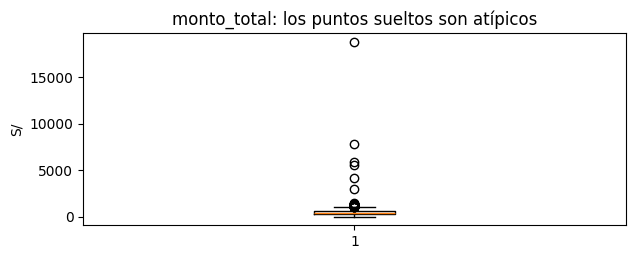

In [11]:
q1, q3 = datos["monto_total"].quantile([0.25, 0.75])
iqr = q3 - q1
limite_sup = q3 + 1.5 * iqr
atipicos = datos[datos["monto_total"] > limite_sup]

print(f"Q1 = {q1:.1f} | Q3 = {q3:.1f} | IQR = {iqr:.1f} | límite superior = {limite_sup:.1f}")
print("Clientes sobre el límite:", len(atipicos))
print("De ellos, con monto mayor a S/ 5 000 (sospechosos de error):", (atipicos["monto_total"] > 5000).sum())

plt.figure(figsize=(7, 2.5))
plt.boxplot(datos["monto_total"])
plt.title("monto_total: los puntos sueltos son atípicos"); plt.ylabel("S/"); plt.show()

In [12]:
# Decisión del equipo: los montos > S/ 5 000 son errores de digitación (12 veces el valor real).
# No los borramos: los reemplazamos por el límite superior ("recorte" o capping).
datos.loc[datos["monto_total"] > 5000, "monto_total"] = limite_sup
print("Monto máximo ahora:", round(datos["monto_total"].max(), 1))

Monto máximo ahora: 4155.7


### 4.5 Tipos de dato

In [13]:
datos["fecha_registro"] = pd.to_datetime(datos["fecha_registro"])
print(datos.dtypes)

id_cliente                    object
edad                         float64
distrito                      object
canal                         object
compras_6m                     int64
monto_total                  float64
dias_ultima_compra           float64
reclamos                       int64
usa_cupon                     object
fecha_registro        datetime64[ns]
se_fue                         int64
dtype: object


### 4.6 Transformación: discretización

1.   Elemento de lista
2.   Elemento de lista



**Discretizar** es convertir un número en **rangos** (categorías ordenadas). Sirve para analizar por grupos y para modelos que trabajan mejor con categorías.

In [14]:
datos["tramo_edad"] = pd.cut(datos["edad"], bins=[17, 25, 40, 60, 80],
                             labels=["18-25", "26-40", "41-60", "61+"])
print(datos["tramo_edad"].value_counts().sort_index())

tramo_edad
18-25    178
26-40    521
41-60    292
61+        9
Name: count, dtype: int64


## 5. Análisis univariado: una variable a la vez

Preguntas que responde:
- ¿Cuál es el valor típico? (media, mediana)
- ¿Qué tan dispersos están los datos? (desviación, rango)
- ¿La distribución es simétrica o tiene cola larga?
- ¿Las clases del target están balanceadas?

In [15]:
numericas = ["edad", "compras_6m", "monto_total", "dias_ultima_compra", "reclamos"]
datos[numericas].describe().round(1)

,edad,compras_6m,monto_total,dias_ultima_compra,reclamos
count,1000.0,1000.0,1000.0,1000.0,1000.0
mean,35.8,5.9,479.7,41.1,0.6
std,10.1,2.5,292.6,41.1,0.8
min,18.0,0.0,0.0,0.0,0.0
25%,29.0,4.0,292.6,11.0,0.0
50%,36.0,6.0,428.0,29.0,0.0
75%,42.0,7.0,595.3,58.0,1.0
max,71.0,18.0,4155.7,287.0,5.0


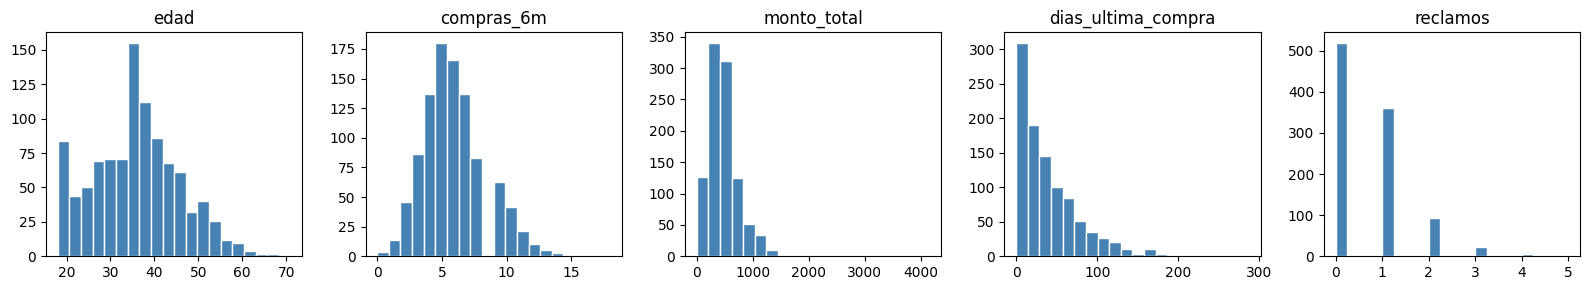

In [16]:
fig, ax = plt.subplots(1, 5, figsize=(16, 3))
for i, col in enumerate(numericas):
    ax[i].hist(datos[col], bins=20, color="steelblue", edgecolor="white")
    ax[i].set_title(col)
plt.tight_layout(); plt.show()

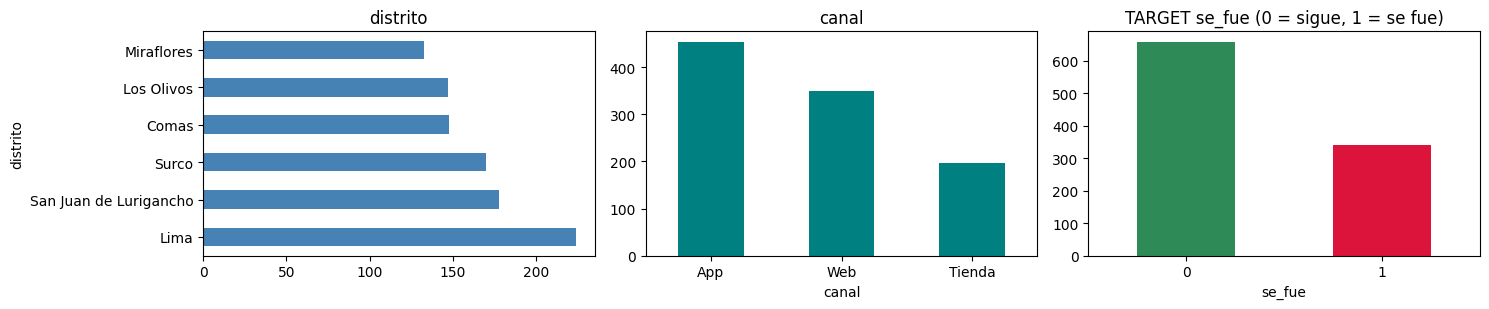

Proporción de clientes que se fueron: 34.2 %


In [17]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.2))
datos["distrito"].value_counts().plot(kind="barh", ax=ax[0], color="steelblue"); ax[0].set_title("distrito")
datos["canal"].value_counts().plot(kind="bar", ax=ax[1], color="teal", rot=0); ax[1].set_title("canal")
datos["se_fue"].value_counts().sort_index().plot(kind="bar", ax=ax[2], color=["seagreen", "crimson"], rot=0)
ax[2].set_title("TARGET se_fue (0 = sigue, 1 = se fue)")
plt.tight_layout(); plt.show()
print("Proporción de clientes que se fueron:", round(datos["se_fue"].mean() * 100, 1), "%")

**Conclusiones que se escriben en el informe (ejemplo):**
- `dias_ultima_compra` y `monto_total` tienen **cola larga a la derecha**: muchos valores bajos y pocos muy altos.
- Alrededor de un tercio de los clientes se fue: las clases están **algo desbalanceadas**, pero no de forma extrema.

## 6. Análisis bivariado: cada variable frente al target

```text
Numérica vs target    → boxplot por grupo  (¿cambia la variable entre los que se van y los que no?)
Categórica vs target  → tasa de abandono por categoría (¿qué % se va en cada grupo?)
Numérica vs numérica  → dispersión (scatter) y correlación
```

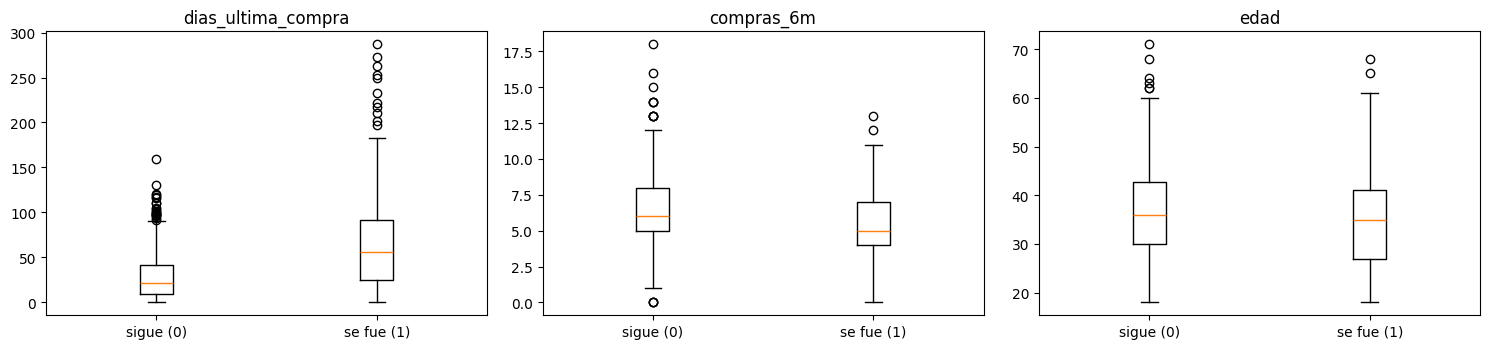

        dias_ultima_compra  compras_6m  edad
se_fue                                      
0                     21.0         6.0  36.0
1                     55.5         5.0  35.0


In [18]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
for i, col in enumerate(["dias_ultima_compra", "compras_6m", "edad"]):
    grupos = [datos.loc[datos["se_fue"] == 0, col], datos.loc[datos["se_fue"] == 1, col]]
    ax[i].boxplot(grupos)
    ax[i].set_xticks([1, 2], ["sigue (0)", "se fue (1)"])
    ax[i].set_title(col)
plt.tight_layout(); plt.show()

print(datos.groupby("se_fue")[["dias_ultima_compra", "compras_6m", "edad"]].median())

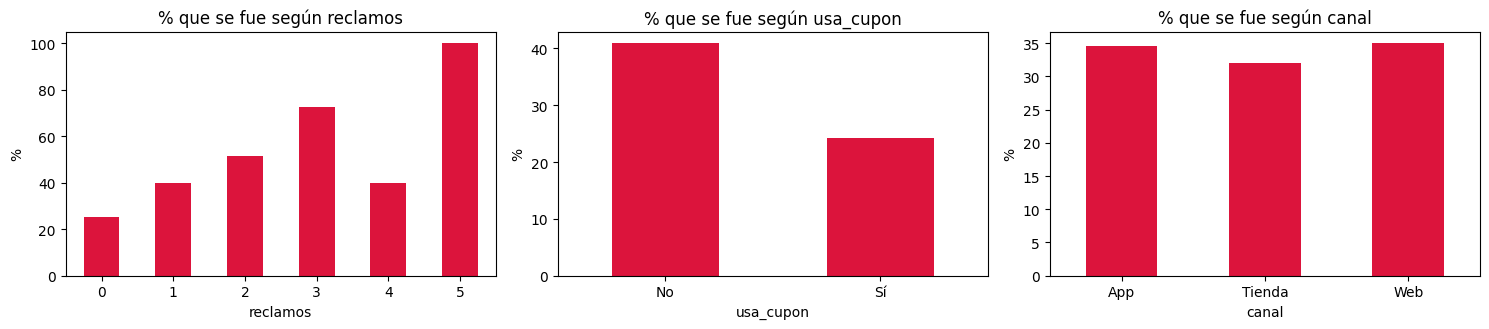

In [19]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.4))
for i, col in enumerate(["reclamos", "usa_cupon", "canal"]):
    tasa = datos.groupby(col)["se_fue"].mean() * 100
    tasa.plot(kind="bar", ax=ax[i], color="crimson", rot=0)
    ax[i].set_title(f"% que se fue según {col}"); ax[i].set_ylabel("%")
plt.tight_layout(); plt.show()

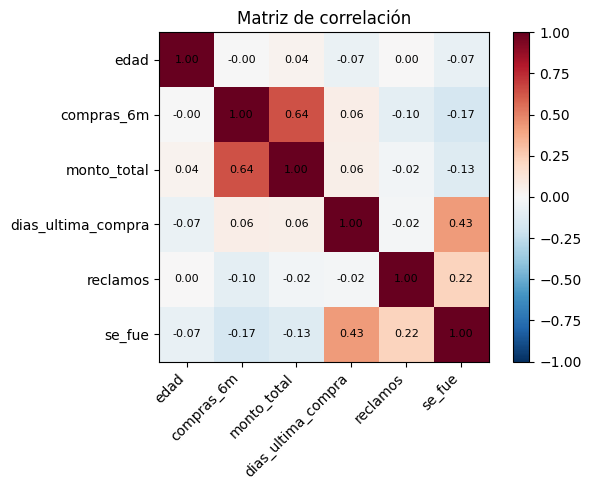

In [20]:
corr = datos[numericas + ["se_fue"]].corr()
plt.figure(figsize=(6.5, 5))
plt.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(len(corr)), corr.columns, rotation=45, ha="right"); plt.yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        plt.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
plt.title("Matriz de correlación"); plt.tight_layout(); plt.show()

**Cómo leer la correlación:** va de −1 a 1. Cerca de 0 = no hay relación lineal. Positiva = suben juntas. Negativa = una sube y la otra baja. Aquí `dias_ultima_compra` es la más relacionada con `se_fue`.

## 7. Hipótesis sobre la data

Una hipótesis es una **afirmación que se puede comprobar con los datos**. Se escribe antes de confirmar y luego se valida.

| # | Hipótesis | Cómo se comprueba |
|---|---|---|
| H1 | Los clientes con más días sin comprar se van más | Comparar la tasa de abandono por tramos de recencia |
| H2 | Los clientes con reclamos se van más | Tasa con 0 reclamos vs con 1 o más |
| H3 | Usar cupón reduce el abandono | Tasa con cupón vs sin cupón |
| H4 | Los clientes de la app se van menos que los de la web | Tasa por canal |

In [21]:
tasa = lambda filtro: round(datos.loc[filtro, "se_fue"].mean() * 100, 1)

print("H2 · Sin reclamos:", tasa(datos["reclamos"] == 0), "% | Con reclamos:", tasa(datos["reclamos"] > 0), "%")
print("H3 · Con cupón:   ", tasa(datos["usa_cupon"] == "Sí"), "% | Sin cupón:   ", tasa(datos["usa_cupon"] == "No"), "%")
print("H4 · App:", tasa(datos["canal"] == "App"), "% | Web:", tasa(datos["canal"] == "Web"), "% | Tienda:", tasa(datos["canal"] == "Tienda"), "%")

H2 · Sin reclamos: 25.2 % | Con reclamos: 43.9 %
H3 · Con cupón:    24.3 % | Sin cupón:    40.9 %
H4 · App: 34.6 % | Web: 35.0 % | Tienda: 32.0 %


**Lectura:** H2 y H3 se apoyan en los datos (las diferencias son grandes). H4 **no** se apoya: las tasas por canal son casi iguales. Descartar una hipótesis también es un buen resultado del análisis. H1 se comprueba en la sección 8, después de crear la variable de tramos de recencia.

**Para ir más allá (opcional):** la prueba chi-cuadrado indica si una diferencia entre grupos podría deberse al azar (p-valor < 0.05 → diferencia significativa).

In [22]:
from scipy.stats import chi2_contingency
for col in ["usa_cupon", "canal"]:
    tabla = pd.crosstab(datos[col], datos["se_fue"])
    chi2, p, _, _ = chi2_contingency(tabla)
    print(f"{col}: p-valor = {p:.4f}", "→ diferencia significativa" if p < 0.05 else "→ no significativa")

usa_cupon: p-valor = 0.0000 → diferencia significativa
canal: p-valor = 0.7596 → no significativa


## 8. Ingeniería de características

Crear, transformar y elegir las variables que el modelo usará.

```text
8.1 Crear nuevas features        a partir de las existentes
8.2 Codificar categóricas         texto → números (one-hot)
8.3 Re-escalado lineal            Min-Max y estandarización
8.4 Re-escalado no lineal         logaritmo para colas largas
8.5 Selección de características  quedarnos con las que más aportan
8.6 Extracción: PCA               resumir muchas variables en pocas
8.7 Rehacer el EDA                con las nuevas features
```

### 8.1 Crear nuevas features

In [23]:
fecha_corte = pd.Timestamp("2026-01-01")
datos["ticket_promedio"] = np.where(datos["compras_6m"] > 0, datos["monto_total"] / datos["compras_6m"], 0).round(2)
datos["antiguedad_meses"] = ((fecha_corte - datos["fecha_registro"]).dt.days / 30).round()
datos["tiene_reclamo"] = (datos["reclamos"] > 0).astype(int)
datos["tramo_recencia"] = pd.cut(datos["dias_ultima_compra"], bins=[-1, 15, 30, 60, 400],
                                 labels=["0-15 días", "16-30", "31-60", "más de 60"])

datos[["ticket_promedio", "antiguedad_meses", "tiene_reclamo", "tramo_recencia"]].head()

,ticket_promedio,antiguedad_meses,tiene_reclamo,tramo_recencia
0,157.71,37.0,0,16-30
1,80.33,12.0,1,0-15 días
2,79.11,34.0,0,0-15 días
3,44.82,20.0,0,31-60
4,65.60,23.0,1,más de 60


### 8.2 Codificar categóricas (one-hot)

In [24]:
datos_mod = pd.get_dummies(datos, columns=["distrito", "canal", "usa_cupon"], drop_first=True, dtype=int)
print("Columnas después de codificar:", datos_mod.shape[1])
datos_mod.filter(like="canal_").head(3)

Columnas después de codificar: 21


,canal_Tienda,canal_Web
0,0,1
1,1,0
2,0,0


### 8.3 Re-escalado lineal

```text
Min-Max:          x' = (x − mín) / (máx − mín)          → queda entre 0 y 1
Estandarización:  z  = (x − media) / desviación           → media 0 y desviación 1

Ejemplo con edad (mín 18, máx 71): una persona de 36 años
   Min-Max:  (36 − 18) / (71 − 18) = 18 / 53 ≈ 0.34
```

In [25]:
minmax = MinMaxScaler()
estandar = StandardScaler()
edad_mm = minmax.fit_transform(datos[["edad"]])
edad_z = estandar.fit_transform(datos[["edad"]])
print("Edad original:", datos["edad"].iloc[:3].tolist())
print("Min-Max:      ", edad_mm[:3].ravel().round(2).tolist())
print("Estandarizada:", edad_z[:3].ravel().round(2).tolist())

Edad original: [39.0, 25.0, 44.0]
Min-Max:       [0.4, 0.13, 0.49]
Estandarizada: [0.31, -1.07, 0.81]


### 8.4 Re-escalado no lineal: logaritmo

Cuando una variable tiene **cola larga** (pocos valores muy grandes), el logaritmo la "comprime" y la vuelve más simétrica. Usamos `log1p(x) = log(1 + x)` para que funcione también con x = 0.

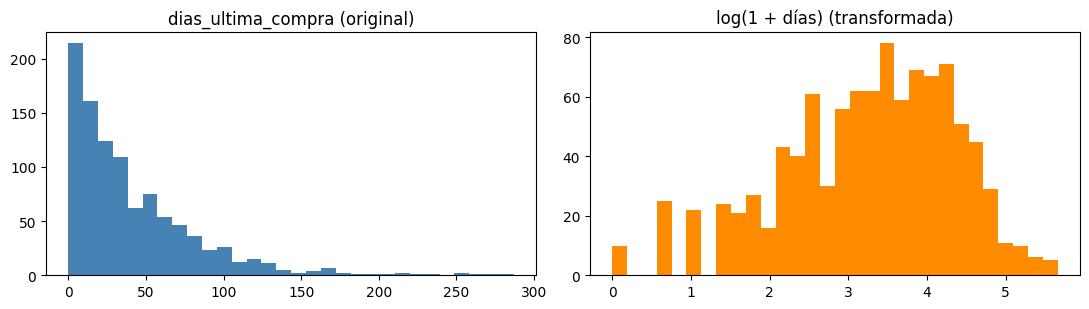

In [26]:
datos["log_monto"] = np.log1p(datos["monto_total"])
datos["log_dias"] = np.log1p(datos["dias_ultima_compra"])

fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].hist(datos["dias_ultima_compra"], bins=30, color="steelblue"); ax[0].set_title("dias_ultima_compra (original)")
ax[1].hist(datos["log_dias"], bins=30, color="darkorange"); ax[1].set_title("log(1 + días) (transformada)")
plt.tight_layout(); plt.show()

### 8.5 Selección de características

Medimos cuánta información aporta cada variable sobre el target con la **información mutua** (0 = nada; más alto = más útil). A diferencia de la correlación, también capta relaciones no lineales.

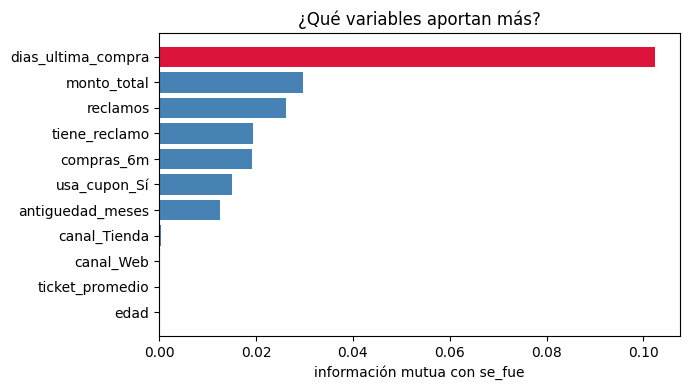

dias_ultima_compra    0.102
monto_total           0.030
reclamos              0.026
tiene_reclamo         0.019
compras_6m            0.019
usa_cupon_Sí          0.015
antiguedad_meses      0.013
canal_Tienda          0.000
canal_Web             0.000
ticket_promedio       0.000
edad                  0.000
dtype: float64


In [27]:
candidatas = ["edad", "compras_6m", "monto_total", "dias_ultima_compra", "reclamos",
              "ticket_promedio", "antiguedad_meses", "tiene_reclamo", "usa_cupon_Sí", "canal_Tienda", "canal_Web"]
X = datos_mod.assign(ticket_promedio=datos["ticket_promedio"], antiguedad_meses=datos["antiguedad_meses"],
                     tiene_reclamo=datos["tiene_reclamo"])[candidatas]
# Indicamos cuáles son discretas (conteos y columnas 0/1) para que el cálculo sea más preciso
discretas = [c in ["compras_6m", "reclamos", "tiene_reclamo", "usa_cupon_Sí", "canal_Tienda", "canal_Web"] for c in candidatas]
mi = pd.Series(mutual_info_classif(X, datos["se_fue"], discrete_features=discretas, random_state=0),
               index=candidatas).sort_values()

plt.figure(figsize=(7, 4))
plt.barh(mi.index, mi.values, color=["crimson" if v == mi.max() else "steelblue" for v in mi.values])
plt.xlabel("información mutua con se_fue"); plt.title("¿Qué variables aportan más?"); plt.tight_layout(); plt.show()
print(mi.sort_values(ascending=False).round(3))

**Lectura:** `dias_ultima_compra` es la que más aporta. `edad`, `ticket_promedio` y el canal aportan prácticamente nada: son candidatas a no usarse en el modelo. Este resultado coincide con lo que vimos en el análisis bivariado.

### 8.6 Extracción de características: PCA

El **Análisis de Componentes Principales (PCA)** combina varias variables numéricas en pocas "componentes" nuevas que conservan la mayor parte de la información (varianza). Sirve para **visualizar** datos de muchas dimensiones y para reducir variables.

Paso obligatorio antes de PCA: **estandarizar**, para que ninguna variable domine por su escala.

Varianza explicada por cada componente: [0.277 0.178]
Total explicado con 2 componentes: 45.5 %


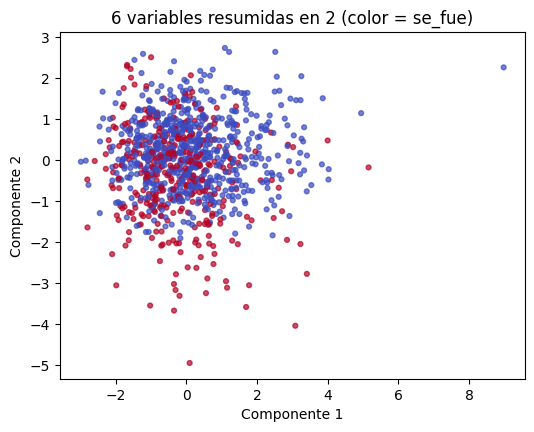

In [28]:
num_pca = ["edad", "compras_6m", "monto_total", "dias_ultima_compra", "reclamos", "antiguedad_meses"]
X_z = StandardScaler().fit_transform(datos[num_pca])
pca = PCA(n_components=2)
componentes = pca.fit_transform(X_z)

print("Varianza explicada por cada componente:", pca.explained_variance_ratio_.round(3))
print("Total explicado con 2 componentes:", round(pca.explained_variance_ratio_.sum() * 100, 1), "%")

plt.figure(figsize=(6, 4.5))
plt.scatter(componentes[:, 0], componentes[:, 1], c=datos["se_fue"], cmap="coolwarm", s=12, alpha=.7)
plt.xlabel("Componente 1"); plt.ylabel("Componente 2"); plt.title("6 variables resumidas en 2 (color = se_fue)")
plt.show()

**Lectura:** 2 componentes conservan solo una parte de la información; aquí PCA sirve sobre todo para **ver** los datos en 2D. Si para conservar el 80–90 % de la varianza hacen falta casi tantas componentes como variables, no conviene reducir.

### 8.7 Rehacer el análisis exploratorio con las nuevas features (comprobar H1)

tramo_recencia
0-15 días    17.6
16-30        23.2
31-60        33.6
más de 60    66.7
Name: se_fue, dtype: float64


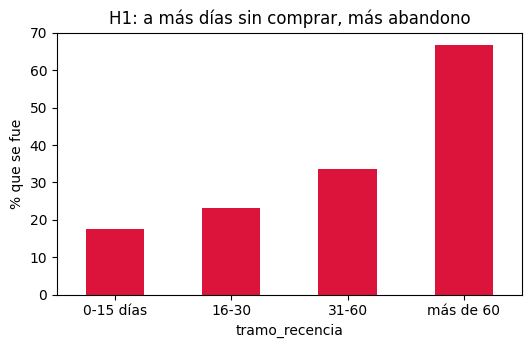

In [29]:
tasa_recencia = datos.groupby("tramo_recencia", observed=True)["se_fue"].mean() * 100
print(tasa_recencia.round(1))

plt.figure(figsize=(6, 3.4))
tasa_recencia.plot(kind="bar", color="crimson", rot=0)
plt.ylabel("% que se fue"); plt.title("H1: a más días sin comprar, más abandono"); plt.show()

## 9. Reporte y reproducibilidad

El criterio **Reproducibilidad del análisis** exige que otra persona pueda repetir todo y obtener lo mismo. Para eso:

- El cuaderno corre de principio a fin sin errores (`Entorno de ejecución → Reiniciar y ejecutar todo`).
- Se usa una semilla fija cuando hay azar (`random_state=0`, `default_rng(42)`).
- Se guarda el dataset limpio y con las nuevas features.
- Cada decisión de limpieza queda escrita (por qué se imputó con la mediana, por qué se recortó un atípico).

In [30]:
datos.to_csv("clientes_limpio.csv", index=False)
print("Archivo guardado: clientes_limpio.csv |", datos.shape[0], "filas y", datos.shape[1], "columnas")

Archivo guardado: clientes_limpio.csv | 1000 filas y 18 columnas


## 10. Ejercicios para practicar

Resuélvelos en las celdas vacías. Puedes copiar y adaptar el código de las secciones anteriores.

### Ejercicio 1 · Diccionario de datos
Agrega al diccionario de la sección 3 las nuevas columnas `tramo_edad`, `ticket_promedio` y `tiene_reclamo`, con su descripción y tipo.

In [31]:
# Escribe tu código aquí

**Respuesta:**

### Ejercicio 2 · Nulos con otra estrategia
Vuelve a cargar los datos y rellena la edad con la **media** en vez de la mediana. ¿Cambia mucho el resultado? ¿Por qué la mediana suele ser más segura?

In [32]:
# Escribe tu código aquí

**Respuesta:**

### Ejercicio 3 · Atípicos en otra variable
Aplica la regla del IQR a `dias_ultima_compra`. ¿Cuántos atípicos hay? ¿Los eliminarías? Justifica.

In [33]:
# Escribe tu código aquí

**Respuesta:**

### Ejercicio 4 · Bivariado
Calcula y grafica el % de clientes que se fue según `tramo_edad`. ¿La edad parece influir?

In [34]:
# Escribe tu código aquí

**Respuesta:**

### Ejercicio 5 · Nueva hipótesis
Formula una hipótesis sobre `ticket_promedio` y compruébala comparando su mediana entre los que se fueron y los que no.

In [35]:
# Escribe tu código aquí

**Respuesta:**

### Ejercicio 6 · PCA
Repite el PCA con **3 componentes**. ¿Qué porcentaje de la varianza explican ahora?

In [36]:
# Escribe tu código aquí

**Respuesta:**